Nodos altos: [5 0 3]
Cores Permitidas Altura: [2 3 5]
Número mínimo de cores: 6


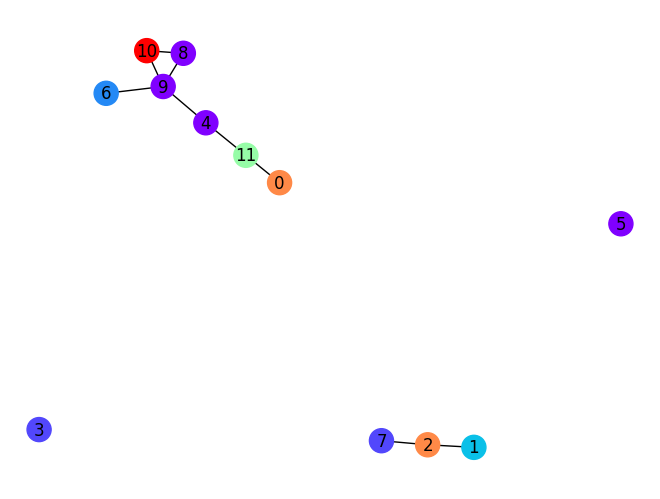

In [ ]:
import random
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import itertools

# Parameters
num_nodes = 12
num_edges = 9
mutation_rate = 0.1
tournament_size = 5
population_size = 30
max_generations = 500

def initialize_population(population_size, num_nodes):
    population = []

    for _ in range(population_size):
        # Initialize the population with one color for each vertex
        chromosome = np.zeros(num_nodes, dtype=int)
        population.append(chromosome)

    return np.array(population)

def fitness_function(chromosome, graph, high_nodes, allowed_height_colors):
    # Initialize a set to store the colors in use
    used_colors = set()

    # Initialize the fitness value
    fitness_value = 0

    # Adjacent vertices must have different colors
    for edge in graph.edges:
        node1, node2 = edge
        color_node1 = chromosome[node1]
        color_node2 = chromosome[node2]
        used_colors.add(color_node1)
        used_colors.add(color_node2)
        # Penalize adjacent vertices with the same color
        if color_node1 == color_node2:
            fitness_value += 1

    # Height constraint
    for node, color in zip(high_nodes, allowed_height_colors):
        if chromosome[node] != color:
            fitness_value += 1

    return len(used_colors), fitness_value  # Return both the number of colors and the fitness value

def selection(population, fitness_values, tournament_size):
    selected_parents = []

    for _ in range(len(population)):
        tournament_indices = np.random.choice(len(population), size=tournament_size, replace=False)
        tournament_fitness = [fitness_values[i] for i in tournament_indices]
        selected_index = tournament_indices[np.argmin([fitness[1] for fitness in tournament_fitness])]
        selected_parents.append(population[selected_index])

    return selected_parents

def crossover(parent1, parent2):
    crossover_point = np.random.randint(1, len(parent1) - 1)
    child1 = np.concatenate((parent1[:crossover_point], parent2[crossover_point:]))
    child2 = np.concatenate((parent2[:crossover_point], parent1[crossover_point:]))
    return child1, child2

def mutate(num_colors, child, mutation_rate):
    mutated_child = np.copy(child)
    for i in range(len(mutated_child)):
        if np.random.rand() < mutation_rate:
            mutated_child[i] = np.random.randint(1, num_colors + 1)
    return mutated_child

def replace_population(population, new_generation, fitness_values, graph, high_nodes, allowed_height_colors):
    for i in range(len(population)):
        if fitness_function(new_generation[i], graph, high_nodes, allowed_height_colors)[1] < fitness_values[i][1]:
            population[i] = new_generation[i]

def check_stop_condition(generation, max_generations, best_historical_fitness, graph, population, high_nodes, allowed_height_colors):
    if generation >= max_generations:
        return True

    # Check whether all vertices have different colors
    for chromosome in population:
        if fitness_function(chromosome, graph, high_nodes, allowed_height_colors)[1] == 0:
            return True

    return False

def create_random_graph(num_nodes, num_edges):
    graph = nx.gnm_random_graph(num_nodes, num_edges)
    return graph

def genetic_algorithm(population, graph, num_nodes, max_generations, high_nodes, allowed_height_colors):
    best_solution = None
    best_num_colors = float('inf')
    best_fitness = float('inf')

    for generation in range(max_generations):
        fitness_values = [fitness_function(chromosome, graph, high_nodes, allowed_height_colors) for chromosome in population]

        best_index = np.argmin([fitness[1] for fitness in fitness_values])
        current_best_fitness = fitness_values[best_index][1]
        current_best_num_colors = fitness_values[best_index][0]

        if current_best_fitness < best_fitness:
            best_solution = population[best_index]
            best_num_colors = current_best_num_colors
            best_fitness = current_best_fitness

        selected_parents = selection(population, fitness_values, tournament_size)

        new_generation = []
        for i in range(0, len(selected_parents), 2):
            parent1 = selected_parents[i]
            parent2 = selected_parents[i + 1] if i + 1 < len(selected_parents) else selected_parents[i]
            child1, child2 = crossover(parent1, parent2)
            child1 = mutate(num_nodes, child1, mutation_rate)
            child2 = mutate(num_nodes, child2, mutation_rate)
            new_generation.extend([child1, child2])

        replace_population(population, new_generation, fitness_values, graph, high_nodes, allowed_height_colors)

        if check_stop_condition(generation, max_generations, best_fitness, graph, population, high_nodes, allowed_height_colors):
            break

    return best_solution, best_num_colors, best_fitness

def plot_graph(graph, best_solution):
    node_colors = [best_solution[node - 1] for node in graph.nodes]
    position = nx.spring_layout(graph)
    nx.draw(graph, position, node_color=node_colors, with_labels=True, cmap=plt.cm.rainbow)
    plt.show()

def main():
    # Create a random graph
    graph = create_random_graph(num_nodes, num_edges)

    # Run the genetic algorithm
    population = initialize_population(population_size, num_nodes)

    high_nodes = np.random.choice(num_nodes, size=np.random.randint(1, num_nodes), replace=False)
    allowed_height_colors = np.random.choice(range(1, num_nodes + 1), size=len(high_nodes), replace=True)

    print("High nodes:", high_nodes)
    print("Allowed height colors:", allowed_height_colors)

    best_solution, num_colors_used, best_fitness = genetic_algorithm(population, graph, num_nodes, max_generations, high_nodes, allowed_height_colors)

    print("Minimum number of colors:", num_colors_used)
    plot_graph(graph, best_solution)

if __name__ == "__main__":
    main()